# 04 · Кластеризация: сохранённый отрицательный результат

## tl;dr

Прежние FCM/KMeans/GMM не дали устойчивого клинического разделения. Все расчёты сохранены как исторические; прежние разбиения не доказывают независимость пациенток. Ветка закрыта для дальнейшего поиска диагнозов по кластерам.


## Context & Methods
### Key Assumptions
Здесь воспроизводится чтение прежнего label-free поиска; результаты и модели не перезаписываются. Его группировка по файлам не равна новой группировке префиксов. Слабая ассоциация не доказывает отсутствие любой структуры, но не даёт оснований для клинического назначения кластеров.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · сохранённые таблицы

In [5]:
legacy=ROOT/'research/experiments/ctg_uci'
association=pd.read_csv(legacy/'cluster_association.csv')
summary=pd.read_csv(legacy/'cluster_test_summary.csv')
display(association.round(4));display(summary[['algorithm','cluster','segments','source_files','path_fraction','enrichment','enrichment_low','enrichment_high']].round(3))


,algorithm,split,k,ari,nmi,silhouette,mean_membership_entropy
0,FCM,test,2,0.0741,0.1215,0.2355,0.6599
1,FCM,train,2,0.0374,0.0902,0.1986,0.6858
2,FCM,validation,2,0.0138,0.0952,0.2600,0.6382
3,GMM,test,2,-0.0024,0.0535,0.1994,0.0359
4,GMM,train,2,0.0041,0.0393,0.1675,0.0251
5,GMM,validation,2,-0.0005,0.0210,0.1861,0.0424
6,KMeans,test,2,0.0913,0.1294,0.2370,0.0000
7,KMeans,train,2,0.0474,0.0950,0.1968,0.0000
8,KMeans,validation,2,0.0244,0.1008,0.2582,0.0000


,algorithm,cluster,segments,source_files,path_fraction,enrichment,enrichment_low,enrichment_high
0,FCM,0,202,47,0.069,0.842,0.222,1.925
1,FCM,1,223,41,0.094,1.143,0.000,1.643
2,GMM,0,248,55,0.056,0.685,0.194,1.547
3,GMM,1,177,40,0.119,1.441,0.000,2.088
4,KMeans,0,230,42,0.091,1.109,0.000,1.607
5,KMeans,1,195,45,0.072,0.872,0.227,2.004


## Results · историческое согласие с экспертной меткой

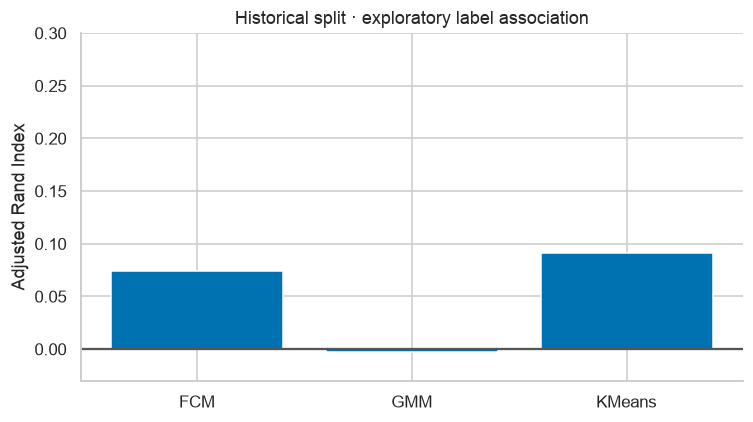

In [7]:
test=association[association.split=='test']
fig,ax=plt.subplots(figsize=(7,4));ax.bar(test.algorithm,test.ari,color='#0072b2')
ax.set(ylabel='Adjusted Rand Index',title='Historical split · exploratory label association',ylim=(-.03,.3));ax.axhline(0,color='#555555')
fig.tight_layout();save_show('uci04_closed_clustering.png')
(UCI/'clustering_branch_status.json').write_text(json.dumps({'status':'closed_for_clinical_risk_use','historical_results_preserved':True,'new_label_guided_search':False},indent=2))


## Takeaways
FCM/KMeans/GMM не приняты как модели клинического риска. Старые исходные таблицы и модели сохранены; повторять поиск по удобной метке не требуется. Сжатие и устойчивость разобраны в [06](06_clustering_embeddings_grid_search.ipynb).
